<a href="https://colab.research.google.com/github/vi-xoxo/BigData26_KelasB_2311533010_Irgi-Fatihul-Ihsan/blob/main/Praktikum3/BD_KELAS_B_PO3_2311533010_IRGI_FATIHUL_IHSAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 3 — Pengumpulan dan Prapemrosesan Data untuk Big Data


## K-1. Menyiapkan Lingkungan dan Memindahkan Perkakas dari Praktikum 1
Cek versi pustaka, mount Google Drive, buat folder kerja, dan siapkan `ukur()` (waktu & memori) serta `catat_sumber()` (lineage).
Semua artefak disimpan ke `/content/drive/MyDrive/BigData/Praktikum3`.

In [1]:
import sys, time, os, json, sqlite3, gc
import pandas as pd, numpy as np, psutil
for nama in ["pandas", "numpy", "pyarrow", "requests", "sklearn", "sqlalchemy"]:
    try:
        mod = __import__(nama)
        print(f"{nama:11s}: {mod.__version__}")
    except ImportError:
        print(f"{nama:11s}: BELUM TERPASANG")
from google.colab import drive
drive.mount("/content/drive")
DIR_MENTAH = "/content/lapisan_mentah"
DIR_KURASI = "/content/lapisan_terkurasi"
DIR_SIMPAN = "/content/drive/MyDrive/BigData/Praktikum3"
for d in (DIR_MENTAH, DIR_KURASI, DIR_SIMPAN):
    os.makedirs(d, exist_ok=True)
# --- Dipakai kembali dari Praktikum 1 / K-3 ---
proses = psutil.Process(os.getpid())
catatan = []
def rss_mb():
    return proses.memory_info().rss / 1024**2
def ukur(label, fungsi):
    m0, t0 = rss_mb(), time.perf_counter()
    hasil = fungsi()
    detik = time.perf_counter() - t0
    catatan.append({"langkah": label, "detik": round(detik, 2),
                    "delta_rss_mb": round(rss_mb() - m0, 1)})
    print(f"[{label}] {detik:.2f} s")
    return hasil
# --- Baru di Praktikum 3: catatan asal-usul data (lineage) ---
lineage = []
def catat_sumber(nama, asal, jumlah_baris, keterangan=""):
    lineage.append({
        "sumber": nama, "asal": asal,
        "diambil_pada": pd.Timestamp.now("UTC").isoformat(),
        "jumlah_baris": jumlah_baris, "keterangan": keterangan,
    })
    print(f"[lineage] {nama}: {jumlah_baris:,} baris")

pandas     : 2.2.3
numpy      : 2.1.3
pyarrow    : 23.0.1
requests   : 2.32.4
sklearn    : 1.6.1
sqlalchemy : 2.1.1
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Interpretasi:** `catatan` merekam biaya komputasi (waktu & memori), `lineage` merekam asal-usul data. Keduanya disimpan sebagai artefak di K-10.

## K-2. Akuisisi 1 — Unduhan Berkala yang Tahan Gagal
Unduh ke berkas sementara `.part`, cek ukuran, lalu `os.replace` (atomik). Ada *retry* dengan *exponential backoff* dan *cache* agar aman dijalankan ulang.

In [2]:
import requests, shutil
def unduh_aman(url, tujuan, percobaan=3, jeda_awal=2):
    """Unduh dengan retry + penulisan atomik. Melewati unduhan bila file sudah ada."""
    if os.path.exists(tujuan) and os.path.getsize(tujuan) > 0:
        print("cache ditemukan:", os.path.basename(tujuan))
        return tujuan
    sementara = tujuan + ".part"
    for i in range(percobaan):
        try:
            with requests.get(url, stream=True, timeout=60) as r:
                r.raise_for_status()
                with open(sementara, "wb") as f:
                    shutil.copyfileobj(r.raw, f)
            if os.path.getsize(sementara) == 0:
                raise IOError("berkas kosong")
            os.replace(sementara, tujuan)  # atomik
            return tujuan
        except Exception as e:
            jeda = jeda_awal * (2 ** i)  # exponential backoff
            print(f"percobaan {i+1} gagal ({e}); menunggu {jeda}s")
            time.sleep(jeda)
    raise RuntimeError(f"gagal mengunduh setelah {percobaan} percobaan: {url}")

URL_TRIP = ("https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2023-01.parquet")
URL_ZONA = ("https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv")
PATH_TRIP = os.path.join(DIR_MENTAH, "yellow_tripdata_2023-01.parquet")
PATH_ZONA = os.path.join(DIR_MENTAH, "taxi_zone_lookup.csv")
ukur("unduh trip", lambda: unduh_aman(URL_TRIP, PATH_TRIP))
ukur("unduh zona", lambda: unduh_aman(URL_ZONA, PATH_ZONA))
for pth in (PATH_TRIP, PATH_ZONA):
    print(os.path.basename(pth), "->", round(os.path.getsize(pth)/1024**2, 2), "MB")
KOLOM = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "passenger_count",
         "trip_distance", "PULocationID", "DOLocationID", "payment_type",
         "fare_amount", "tip_amount", "total_amount"]
trip = ukur("baca trip", lambda: pd.read_parquet(PATH_TRIP, columns=KOLOM))
zona = pd.read_csv(PATH_ZONA, compression='gzip')
catat_sumber("trip", URL_TRIP, len(trip), "Parquet bulanan TLC")
catat_sumber("zona", URL_ZONA, len(zona), "tabel dimensi 265 zona")
zona.head()

cache ditemukan: yellow_tripdata_2023-01.parquet
[unduh trip] 0.00 s
cache ditemukan: taxi_zone_lookup.csv
[unduh zona] 0.00 s
yellow_tripdata_2023-01.parquet -> 45.46 MB
taxi_zone_lookup.csv -> 0.0 MB
[baca trip] 1.64 s
[lineage] trip: 3,066,766 baris
[lineage] zona: 265 baris


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [3]:
# simpan jumlah baris awal untuk analisis susut data (O-6)
n_mentah = len(trip)
print(f"baris mentah trip: {n_mentah:,}")

baris mentah trip: 3,066,766


**Interpretasi:** `PULocationID` dan `DOLocationID` ikut dibaca karena menjadi kunci join di K-8. Angka ukuran file & jumlah baris yang muncul adalah hasil eksekusi Anda sendiri.

## K-3. Akuisisi 2 — Memanggil API JSON (Open-Meteo)
Tiga hal: parameter dikirim sebagai `dict`, struktur respons divalidasi, dan ada jeda/retry untuk kode 429 & 5xx.

In [4]:
API_CUACA = "https://archive-api.open-meteo.com/v1/archive"
def ambil_cuaca(mulai, selesai, lat=40.7128, lon=-74.0060, percobaan=3):
    parameter = {
        "latitude": lat, "longitude": lon,
        "start_date": mulai, "end_date": selesai,
        "hourly": "temperature_2m,precipitation",
        "timezone": "America/New_York",
    }
    for i in range(percobaan):
        r = requests.get(API_CUACA, params=parameter, timeout=60)
        if r.status_code == 200:
            data = r.json()
            if "hourly" not in data:  # validasi struktur
                raise ValueError("kunci 'hourly' tidak ada pada respons")
            return pd.DataFrame(data["hourly"])
        if r.status_code in (429, 500, 502, 503):  # layak dicoba ulang
            time.sleep(2 ** i)
            continue
        r.raise_for_status()  # galat lain: hentikan
    raise RuntimeError("API cuaca tidak merespons dengan benar")

cuaca = ukur("ambil cuaca", lambda: ambil_cuaca("2023-01-01", "2023-01-31"))
cuaca["time"] = pd.to_datetime(cuaca["time"])
cuaca = cuaca.rename(columns={"time": "jam_mulai",
                              "temperature_2m": "suhu_c",
                              "precipitation": "hujan_mm"})
catat_sumber("cuaca", API_CUACA, len(cuaca), "Open-Meteo hourly archive")
cuaca.head()

[ambil cuaca] 0.10 s
[lineage] cuaca: 744 baris


,jam_mulai,suhu_c,hujan_mm
0,2023-01-01 00:00:00,10.9,1.0
1,2023-01-01 01:00:00,10.6,1.0
2,2023-01-01 02:00:00,10.6,0.1
3,2023-01-01 03:00:00,10.5,0.0
4,2023-01-01 04:00:00,9.8,0.0


In [5]:
# Pemeriksaan: jumlah baris cuaca harus = jumlah jam pada rentang 1-31 Januari 2023
jam_diharapkan = 31 * 24
print("baris cuaca:", len(cuaca), "| jam diharapkan:", jam_diharapkan,
      "| selisih:", jam_diharapkan - len(cuaca))

baris cuaca: 744 | jam diharapkan: 744 | selisih: 0


**Interpretasi:** bila selisih ≠ 0, ada jam yang datanya hilang — itu temuan kualitas data yang harus dilaporkan.

In [6]:
def cuaca_sintetis(mulai="2023-01-01", selesai="2023-01-31", seed=7):
    jam = pd.date_range(mulai, pd.Timestamp(selesai) + pd.Timedelta("23h"), freq="h")
    rng = np.random.default_rng(seed)
    return pd.DataFrame({
        "jam_mulai": jam,
        "suhu_c": np.round(rng.normal(3, 5, len(jam)), 1),
        "hujan_mm": np.round(rng.gamma(0.4, 0.8, len(jam)), 2),
    })
# Pakai hanya jika K-3 gagal:
# cuaca = cuaca_sintetis()
# catat_sumber("cuaca", "sintetis", len(cuaca), "PENGGANTI - bukan data nyata")

## K-5. Akuisisi 3 — Basis Data SQLite dengan Pemuatan Bertahap
Buat basis data kecil (mensimulasikan sistem operasional), baca dengan SQL, lalu baca bertahap memakai `chunksize`.

In [7]:
from sqlalchemy import create_engine
PATH_DB = os.path.join(DIR_MENTAH, "operasional.db")
engine = create_engine(f"sqlite:///{PATH_DB}")
tarif_referensi = pd.DataFrame({
    "payment_type": [1, 2, 3, 4, 5, 6],
    "nama_pembayaran": ["Kartu kredit", "Tunai", "Gratis",
                        "Sengketa", "Tidak diketahui", "Perjalanan batal"],
    "kena_biaya_admin": [1, 0, 0, 0, 0, 0],
})
tarif_referensi.to_sql("tarif_referensi", engine, if_exists="replace", index=False)
# tabel transaksi tiruan untuk latihan pembacaan bertahap
trip.head(300_000).to_sql(
    "trip_operasional", engine, if_exists="replace",
    index=False, chunksize=50_000)
print("Tabel dibuat:", pd.read_sql(
    "SELECT name FROM sqlite_master WHERE type='table'", engine)["name"].tolist())
SQL = """
    SELECT payment_type, COUNT(*) AS jumlah, AVG(total_amount) AS rata_total
    FROM trip_operasional
    WHERE total_amount > 0
    GROUP BY payment_type
    ORDER BY jumlah DESC
"""
ringkas_db = pd.read_sql(SQL, engine)
print(ringkas_db)
# Pembacaan bertahap: agregasi tanpa memuat seluruh tabel ke memori
total_baris = 0
for bagian in pd.read_sql("SELECT trip_distance FROM trip_operasional",
                          engine, chunksize=50_000):
    total_baris += len(bagian)
print("dibaca bertahap:", f"{total_baris:,}", "baris")
tarif_referensi = pd.read_sql("SELECT * FROM tarif_referensi", engine)
catat_sumber("tarif_referensi", PATH_DB, len(tarif_referensi),
             "tabel dimensi dari basis data operasional")

Tabel dibuat: ['tarif_referensi', 'trip_operasional']
   payment_type  jumlah  rata_total
0             1  226967   31.339172
1             2   66504   25.218836
2             4    2082   26.611114
3             3    1553   22.089691
dibaca bertahap: 300,000 baris
[lineage] tarif_referensi: 6 baris


**Interpretasi:** memakai *engine* SQLAlchemy menghindari `UserWarning` pandas ≥ 2.0 dan polanya sama untuk PostgreSQL/MySQL (cukup ganti URL).

## K-6. Profiling Kualitas Data pada Enam Dimensi
Kualitas diukur lewat tabel `profil` (per kolom) dan tabel `laporan` (8 aturan: kelengkapan, keunikan, validitas, konsistensi, ketepatan waktu). `laporan` menjadi artefak `laporan_kualitas.csv`.

In [8]:
trip["durasi_menit"] = (
    (trip["tpep_dropoff_datetime"] - trip["tpep_pickup_datetime"])
    .dt.total_seconds() / 60)
def profil_kolom(df):
    baris = []
    for kol in df.columns:
        s = df[kol]
        baris.append({
            "kolom": kol, "tipe": str(s.dtype),
            "persen_hilang": round(100 * s.isna().mean(), 3),
            "nilai_unik": s.nunique(dropna=True),
            "contoh": s.dropna().iloc[0] if s.notna().any() else None,
        })
    return pd.DataFrame(baris)
profil = profil_kolom(trip)
profil

,kolom,tipe,persen_hilang,nilai_unik,contoh
0,tpep_pickup_datetime,datetime64[us],0.000,1610975,2023-01-01 00:32:10
1,tpep_dropoff_datetime,datetime64[us],0.000,1611319,2023-01-01 00:40:36
2,passenger_count,float64,2.339,10,1.0
3,trip_distance,float64,0.000,4387,0.97
4,PULocationID,int64,0.000,257,161
5,DOLocationID,int64,0.000,261,141
6,payment_type,int64,0.000,5,2
7,fare_amount,float64,0.000,6873,9.3
8,tip_amount,float64,0.000,4036,0.0
9,total_amount,float64,0.000,15871,14.3


In [9]:
AWAL, AKHIR = pd.Timestamp("2023-01-01"), pd.Timestamp("2023-02-01")
zona_sah = set(zona["LocationID"])
aturan = {
    "kelengkapan: passenger_count ada": trip["passenger_count"].notna(),
    "keunikan: baris tidak duplikat": ~trip.duplicated(),
    "validitas: jarak 0-100 mil": trip["trip_distance"].between(0.01, 100),
    "validitas: total_amount > 0": trip["total_amount"] > 0,
    "validitas: PULocationID dikenal": trip["PULocationID"].isin(zona_sah),
    "konsistensi: durasi 1-180 menit": trip["durasi_menit"].between(1, 180),
    "konsistensi: total >= fare": trip["total_amount"] >= trip["fare_amount"],
    "ketepatan waktu: dalam Jan 2023": trip["tpep_pickup_datetime"].between(AWAL, AKHIR),
}
laporan = pd.DataFrame([
    {"aturan": nama, "lulus": int(mask.sum()), "gagal": int((~mask).sum()),
     "persen_gagal": round(100 * (~mask).mean(), 3)}
    for nama, mask in aturan.items()
]).sort_values("persen_gagal", ascending=False)
laporan

,aturan,lulus,gagal,persen_gagal
0,kelengkapan: passenger_count ada,2995023,71743,2.339
2,validitas: jarak 0-100 mil,3020816,45950,1.498
5,konsistensi: durasi 1-180 menit,3030383,36383,1.186
3,validitas: total_amount > 0,3040994,25772,0.840
6,konsistensi: total >= fare,3041743,25023,0.816
7,ketepatan waktu: dalam Jan 2023,3066718,48,0.002
1,keunikan: baris tidak duplikat,3066766,0,0.000
4,validitas: PULocationID dikenal,3066766,0,0.000


**Interpretasi:** baca dari atas — aturan dengan persen gagal tertinggi adalah tempat keputusan paling hati-hati. Angka dilaporkan dari hasil eksekusi sendiri.

## K-7. Nilai Hilang dan Duplikat
**Keputusan (ditulis sebelum kode):**
- Kolom yang dibandingkan: `passenger_count` (lihat `persen_hilang` di profil).
- Empat strategi dibandingkan: dibuang, isi median, isi modus, median per jam.
- Strategi terpilih: **tandai (`_hilang`) + isi median per jam** karena hilangnya diduga MAR (bergantung variabel lain, mis. jam/vendor), sambil mempertahankan informasi bahwa nilai itu dulunya hilang. Median global sebagai jaring pengaman.
- Duplikat: periksa dua tingkat (penuh & pada `KUNCI`); hapus yang pada `KUNCI` dengan `keep="first"` setelah dicek dampaknya.

In [10]:
KOL = "passenger_count"
asli = trip[KOL]
print("persen hilang:", round(100 * asli.isna().mean(), 3))
trip["jam"] = trip["tpep_pickup_datetime"].dt.hour
strategi = {
    "1_dibuang": asli.dropna(),
    "2_isi_median": asli.fillna(asli.median()),
    "3_isi_modus": asli.fillna(asli.mode().iloc[0]),
    "4_median_perjam": asli.fillna(trip.groupby("jam")[KOL].transform("median")),
}
banding = pd.DataFrame([
    {"strategi": nama, "n": len(s), "mean": round(s.mean(), 4),
     "median": s.median(), "std": round(s.std(), 4)}
    for nama, s in strategi.items()
])
banding

persen hilang: 2.339


,strategi,n,mean,median,std
0,1_dibuang,2995023,1.3625,1.0,0.8961
1,2_isi_median,3066766,1.3541,1.0,0.8873
2,3_isi_modus,3066766,1.3541,1.0,0.8873
3,4_median_perjam,3066766,1.3541,1.0,0.8873


In [11]:
# Strategi yang dipilih modul ini: tandai + isi per kelompok (lihat G.4)
trip[KOL + "_hilang"] = trip[KOL].isna().astype("int8")
trip[KOL] = trip[KOL].fillna(trip.groupby("jam")[KOL].transform("median"))
trip[KOL] = trip[KOL].fillna(trip[KOL].median())  # jaring pengaman
# Duplikat: periksa dua tingkat
dup_penuh = trip.duplicated().sum()
KUNCI = ["tpep_pickup_datetime", "tpep_dropoff_datetime",
         "PULocationID", "DOLocationID", "total_amount"]
dup_kunci = trip.duplicated(subset=KUNCI).sum()
print(f"duplikat penuh: {dup_penuh:,} | duplikat pada kunci: {dup_kunci:,}")
sebelum = len(trip)
trip = trip.drop_duplicates(subset=KUNCI, keep="first").reset_index(drop=True)
print(f"{sebelum:,} -> {len(trip):,} baris")

duplikat penuh: 0 | duplikat pada kunci: 1
3,066,766 -> 3,066,765 baris


In [12]:
# Tambahan (bukan dari modul): catat jumlah baris setelah deduplikasi untuk O-6
n_setelah_dup = len(trip)
print(f"baris setelah deduplikasi: {n_setelah_dup:,}")

baris setelah deduplikasi: 3,066,765


**Interpretasi:** duplikat pada kunci belum tentu salah data (dua perjalanan berbeda bisa identik). Bila jumlahnya besar, curigai definisi kunci Anda.

## K-8. Outlier, Join dengan Tabel Referensi, dan Penggabungan Berbasis Waktu
**Keputusan (ditulis sebelum kode):**
- Outlier dibandingkan dengan IQR dan Z-score pada `trip_distance`, `durasi_menit`, `total_amount`.
- **Dibuang** hanya baris yang mustahil secara fisik/bisnis: jarak di luar 0,01–100 mil, durasi di luar 1–180 menit, `total_amount ≤ 0`.
- **Ditandai** (bukan dibuang): `tarif_ekstrem` (total > batas atas IQR) karena perjalanan mahal (mis. bandara) adalah kenyataan bisnis.
- **Winsorizing** persentil 99,5% hanya untuk kolom turunan `trip_distance_capped`.
- Semua join: cek keunikan kunci, samakan granularitas, `validate="many_to_one"`, bandingkan jumlah baris.

In [13]:
def batas_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

def ringkas_outlier(df, kolom):
    hasil = []
    for kol in kolom:
        s = df[kol].dropna()
        lo, hi = batas_iqr(s)
        z = (s - s.mean()) / s.std()
        hasil.append({
            "kolom": kol, "batas_bawah": round(lo, 2), "batas_atas": round(hi, 2),
            "outlier_iqr": int(((s < lo) | (s > hi)).sum()),
            "outlier_z3": int((z.abs() > 3).sum()), "p99": round(s.quantile(0.99), 2),
        })
    return pd.DataFrame(hasil)

ringkas_outlier(trip, ["trip_distance", "durasi_menit", "total_amount"])

,kolom,batas_bawah,batas_atas,outlier_iqr,outlier_z3,p99
0,trip_distance,-2.35,6.74,390244,67,20.06
1,durasi_menit,-9.66,35.08,170615,3175,57.25
2,total_amount,-4.55,48.65,371616,87248,101.94


In [14]:
# Tindakan berbeda untuk maksud berbeda (lihat G.5)
layak = (trip["trip_distance"].between(0.01, 100)
         & trip["durasi_menit"].between(1, 180)
         & (trip["total_amount"] > 0))
bersih = trip.loc[layak].copy()
# tandai, jangan buang: outlier bisa jadi memang kenyataan bisnis
lo, hi = batas_iqr(bersih["total_amount"])
bersih["tarif_ekstrem"] = (bersih["total_amount"] > hi).astype("int8")
# winsorizing hanya untuk kolom turunan yang akan dipakai model
batas_atas = bersih["trip_distance"].quantile(0.995)
bersih["trip_distance_capped"] = bersih["trip_distance"].clip(upper=batas_atas)
print(f"{len(trip):,} -> {len(bersih):,} baris "
      f"({100*(1-len(bersih)/len(trip)):.2f}% dibuang)")

3,066,765 -> 2,986,910 baris (2.60% dibuang)


In [15]:
# --- Join 1: tabel zona (dimensi) ---
print("kunci zona unik?", zona["LocationID"].is_unique)  # WAJIB diperiksa
n0 = len(bersih)
bersih = bersih.merge(
    zona[["LocationID", "Borough", "Zone"]]
    .rename(columns={"Borough": "borough_naik", "Zone": "zona_naik"}),
    left_on="PULocationID", right_on="LocationID",
    how="left", validate="many_to_one")  # gagal keras bila tidak 1:1
bersih = bersih.drop(columns="LocationID")
print(f"baris {n0:,} -> {len(bersih):,} (harus sama)")
print("zona tak dikenal:", bersih["zona_naik"].isna().sum())

kunci zona unik? True
baris 2,986,910 -> 2,986,910 (harus sama)
zona tak dikenal: 37609


In [16]:
# --- Join 2: tabel pembayaran dari basis data ---
bersih = bersih.merge(tarif_referensi[["payment_type", "nama_pembayaran"]],
                      on="payment_type", how="left", validate="many_to_one")

In [17]:
# --- Join 3: cuaca, berdasarkan jam (tingkat rincian harus disamakan dulu) ---
bersih["jam_mulai"] = bersih["tpep_pickup_datetime"].dt.floor("h")
n0 = len(bersih)
bersih = bersih.merge(cuaca, on="jam_mulai", how="left", validate="many_to_one")
print(f"baris {n0:,} -> {len(bersih):,}")
print("tanpa data cuaca:", bersih["suhu_c"].isna().sum())

baris 2,986,910 -> 2,986,910
tanpa data cuaca: 37


**Interpretasi:** jumlah baris harus tetap sama setelah setiap left join `many_to_one`; jika tidak, pandas menghentikan proses dengan `MergeError`.

## K-9. Rekayasa Fitur: Encoding dan Scaling Tanpa Kebocoran
**Keputusan:** pisahkan data latih/uji **dulu**; `StandardScaler` dan `OneHotEncoder` di-`fit` hanya pada data latih, uji hanya `transform`. Mean data uji tidak persis 0 = bukti benar.

In [18]:
bersih["hari_minggu"] = bersih["tpep_pickup_datetime"].dt.dayofweek
bersih["akhir_pekan"] = (bersih["hari_minggu"] >= 5).astype("int8")
bersih["kecepatan_mph"] = (bersih["trip_distance"] / (bersih["durasi_menit"] / 60)).round(2)
bersih["tarif_per_mil"] = (bersih["total_amount"] / bersih["trip_distance"]).round(3)
bersih["hujan"] = (bersih["hujan_mm"].fillna(0) > 0.1).astype("int8")
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
FITUR_NUM = ["trip_distance_capped", "durasi_menit", "suhu_c"]
FITUR_KAT = ["nama_pembayaran", "borough_naik"]
contoh = bersih.dropna(subset=FITUR_NUM + FITUR_KAT).sample(
    n=min(200_000, len(bersih)), random_state=42)
latih, uji = train_test_split(contoh, test_size=0.2, random_state=42)

In [19]:
skala = StandardScaler().fit(latih[FITUR_NUM])  # fit HANYA di data latih
latih_num = skala.transform(latih[FITUR_NUM])
uji_num = skala.transform(uji[FITUR_NUM])  # transform saja, tanpa fit ulang
print("mean latih (harus ~0):", latih_num.mean(axis=0).round(3))
print("mean uji (tidak harus 0):", uji_num.mean(axis=0).round(3))
# Bergantung versi: parameter sparse_output ada sejak scikit-learn 1.2
enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
enc.fit(latih[FITUR_KAT])
latih_kat = enc.transform(latih[FITUR_KAT])
print("jumlah kolom hasil one-hot:", latih_kat.shape[1])
print("nama kolom:", enc.get_feature_names_out()[:6], "...")

mean latih (harus ~0): [-0.  0. -0.]
mean uji (tidak harus 0): [ 0.001  0.001 -0.009]
jumlah kolom hasil one-hot: 11
nama kolom: ['nama_pembayaran_Gratis' 'nama_pembayaran_Kartu kredit'
 'nama_pembayaran_Sengketa' 'nama_pembayaran_Tunai' 'borough_naik_Bronx'
 'borough_naik_Brooklyn'] ...


## K-10. Membungkus Jadi Pipeline, Memvalidasi, dan Menyimpan Berpartisi
Kontrak skema (`validasi`) sengaja melempar `AssertionError` agar kegagalan berisik. Fungsi `pipeline` adalah satu fungsi idempoten: input mentah → DataFrame tervalidasi. Hasil ditulis berpartisi menurut `borough_naik`.

In [20]:
KONTRAK = {
    "tpep_pickup_datetime": "datetime64[ns]", "trip_distance": "float64",
    "durasi_menit": "float64", "total_amount": "float64",
    "borough_naik": "object", "nama_pembayaran": "object",
}
def validasi(df, kontrak=KONTRAK):
    masalah = []
    for kol, tipe in kontrak.items():
        if kol not in df.columns:
            masalah.append(f"kolom hilang: {kol}")
        elif not str(df[kol].dtype).startswith(tipe.split("[")[0]):
            masalah.append(f"tipe {kol}: {df[kol].dtype} != {tipe}")
    if df.empty:
        masalah.append("DataFrame kosong")
    if len(df) != len(df.drop_duplicates(subset=KUNCI)):
        masalah.append("masih ada duplikat pada kunci")
    if masalah:
        raise AssertionError("Validasi gagal:\n- " + "\n- ".join(masalah))
    print(f"Validasi lulus: {len(df):,} baris x {df.shape[1]} kolom")
    return df

validasi(bersih);

Validasi lulus: 2,986,910 baris x 26 kolom


In [21]:
def pipeline(path_trip, path_zona, df_cuaca, df_tarif):
    """Satu fungsi, idempoten: input mentah -> DataFrame tervalidasi."""
    df = pd.read_parquet(path_trip, columns=KOLOM)
    z = pd.read_csv(path_zona, compression='gzip')
    df["durasi_menit"] = ((df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"])
                          .dt.total_seconds() / 60)
    df["jam"] = df["tpep_pickup_datetime"].dt.hour
    df["passenger_count"] = df["passenger_count"].fillna(
        df.groupby("jam")["passenger_count"].transform("median"))
    df = df.drop_duplicates(subset=KUNCI)
    df = df[df["trip_distance"].between(0.01, 100)
            & df["durasi_menit"].between(1, 180)
            & (df["total_amount"] > 0)]
    df = (df.merge(z[["LocationID", "Borough"]]
                   .rename(columns={"Borough": "borough_naik"}),
                   left_on="PULocationID", right_on="LocationID",
                   how="left", validate="many_to_one")
            .drop(columns="LocationID")
            .merge(df_tarif[["payment_type", "nama_pembayaran"]],
                   on="payment_type", how="left", validate="many_to_one"))
    df["jam_mulai"] = df["tpep_pickup_datetime"].dt.floor("h")
    df = df.merge(df_cuaca, on="jam_mulai", how="left", validate="many_to_one")
    return validasi(df)

hasil = ukur("pipeline penuh", lambda: pipeline(PATH_TRIP, PATH_ZONA, cuaca, tarif_referensi))

Validasi lulus: 2,986,910 baris x 17 kolom
[pipeline penuh] 7.85 s


In [22]:
OUT = os.path.join(DIR_KURASI, "trips_bersih")
hasil["tanggal"] = hasil["tpep_pickup_datetime"].dt.date.astype(str)
# Tambahan agar idempoten saat sel dijalankan ulang: hapus keluaran lama (overwrite)
if os.path.isdir(OUT):
    shutil.rmtree(OUT)
ukur("tulis parquet berpartisi", lambda: hasil.to_parquet(
    OUT, partition_cols=["borough_naik"], index=False))
print("partisi yang terbentuk:", sorted(os.listdir(OUT))[:5], "...")
# Bukti idempotensi: jalankan ulang, hasil harus identik
ulang = pipeline(PATH_TRIP, PATH_ZONA, cuaca, tarif_referensi)
print("idempoten?", len(ulang) == len(hasil))

[tulis parquet berpartisi] 3.44 s
partisi yang terbentuk: ['borough_naik=Bronx', 'borough_naik=Brooklyn', 'borough_naik=EWR', 'borough_naik=Manhattan', 'borough_naik=Queens'] ...
Validasi lulus: 2,986,910 baris x 17 kolom
idempoten? True


In [23]:
# Artefak yang dikumpulkan
laporan.to_csv(f"{DIR_SIMPAN}/laporan_kualitas.csv", index=False)
pd.DataFrame(lineage).to_csv(f"{DIR_SIMPAN}/lineage.csv", index=False)
pd.DataFrame(catatan).to_csv(f"{DIR_SIMPAN}/pengukuran_kinerja.csv", index=False)
shutil.make_archive(f"{DIR_SIMPAN}/trips_bersih", "zip", OUT)
print(sorted(os.listdir(DIR_SIMPAN)))

['hist_total_amount.png', 'kamus_data.md', 'kamus_data_studi_kasus.md', 'laporan_kualitas.csv', 'laporan_kualitas_komparatif.csv', 'lineage.csv', 'lineage_diagram.png', 'pengukuran_kinerja.csv', 'tabel_analitik.parquet', 'trips_bersih', 'trips_bersih.zip']


**Interpretasi:** partisi per `borough` (kardinalitas rendah, sering jadi filter) memungkinkan *partition pruning*. Mempartisi menurut kolom berkardinalitas tinggi (mis. `LocationID`) menghasilkan ribuan berkas kecil.

## K-11. Pra-pemrosesan Setara dengan PySpark (Tambahan / Stretch)
Pipeline yang setara di Spark local mode. `F.broadcast()` menyalin tabel kecil ke setiap executor (tanpa *shuffle*); `mode("overwrite")` menjaga idempotensi. Jika waktu menipis, kerjakan sebagai tugas mandiri.

In [24]:
!pip uninstall -y dataproc-spark-connect

In [25]:
!pip install pyspark==3.5.1

In [26]:
from pyspark.sql import SparkSession, functions as F
spark = (SparkSession.builder.appName("BD-P02").master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
sdf = spark.read.parquet(PATH_TRIP).select(*KOLOM)
szona = spark.createDataFrame(zona[["LocationID", "Borough"]])
sbersih = (sdf
    .withColumn("durasi_menit",
                (F.col("tpep_dropoff_datetime").cast("timestamp").cast("long")
                 - F.col("tpep_pickup_datetime").cast("timestamp").cast("long")) / 60)
    .filter(F.col("trip_distance").between(0.01, 100))
    .filter(F.col("durasi_menit").between(1, 180))
    .filter(F.col("total_amount") > 0)
    .dropDuplicates(["tpep_pickup_datetime", "tpep_dropoff_datetime",
                     "PULocationID", "DOLocationID", "total_amount"])
    .join(F.broadcast(szona),
          sdf.PULocationID == szona.LocationID, "left")
    .drop("LocationID"))
n_spark = ukur("spark: hitung baris bersih", lambda: sbersih.count())
print("baris bersih Spark:", f"{n_spark:,}")
sbersih.groupBy("Borough").count().orderBy(F.desc("count")).show(10, False)
sbersih.write.mode("overwrite").partitionBy("Borough") \
    .parquet("/content/lapisan_terkurasi/trips_spark")
sbersih.explain()  # cari BroadcastHashJoin, bukan SortMergeJoin
spark.stop()

[spark: hitung baris bersih] 23.11 s
baris bersih Spark: 2,986,910
+-------------+-------+
|Borough      |count  |
+-------------+-------+
|Manhattan    |2659609|
|Queens       |270315 |
|Unknown      |37609  |
|Brooklyn     |15724  |
|Bronx        |3074   |
|NaN          |340    |
|Staten Island|211    |
|EWR          |28     |
+-------------+-------+

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [tpep_pickup_datetime#1, tpep_dropoff_datetime#2, passenger_count#245, trip_distance#247, PULocationID#7L, DOLocationID#8L, payment_type#249L, fare_amount#251, tip_amount#253, total_amount#16, durasi_menit#255, Borough#50]
   +- BroadcastHashJoin [PULocationID#7L], [LocationID#49L], LeftOuter, BuildRight, false
      :- HashAggregate(keys=[DOLocationID#8L, tpep_dropoff_datetime#2, PULocationID#7L, total_amount#16, tpep_pickup_datetime#1], functions=[first(passenger_count#3, false), first(trip_distance#4, false), first(payment_type#9L, false), first(fare_amount#10, false)

In [27]:
# Pemeriksaan silang wajib: pandas (K-8) vs Spark (K-11)
print(f"pandas (K-8)  : {len(bersih):,} baris")
print(f"Spark  (K-11) : {n_spark:,} baris")
print(f"selisih       : {len(bersih) - n_spark:,} baris")

pandas (K-8)  : 2,986,910 baris
Spark  (K-11) : 2,986,910 baris
selisih       : 0 baris


**Interpretasi:** selisih kecil wajar (urutan *dedup* vs *filter* dan penanganan `null` berbeda: pandas dedup dulu baru filter, Spark filter dulu baru dedup). Selisih besar harus diselidiki dan dilaporkan.

---
# O. Analisis Hasil


### O-1. Peta kualitas — tiga aturan yang paling sering gagal

In [28]:
penyebab = {
    "kelengkapan: passenger_count ada": "Nilai kosong pada kolom yang diisi pengemudi/vendor (MAR) -> galat perekaman.",
    "keunikan: baris tidak duplikat": "Baris ganda akibat pengiriman data ulang -> galat perekaman.",
    "validitas: jarak 0-100 mil": "Jarak 0 mil (perjalanan batal / argo tidak berjalan) atau jarak mustahil -> galat perekaman + definisi bisnis.",
    "validitas: total_amount > 0": "Total nol/negatif karena refund, sengketa, atau perjalanan gratis -> definisi bisnis.",
    "validitas: PULocationID dikenal": "ID zona di luar tabel lookup -> asumsi saya tentang rentang 1-265 bisa keliru.",
    "konsistensi: durasi 1-180 menit": "Durasi < 1 menit atau > 3 jam: argo lupa dimatikan / perjalanan batal -> galat perekaman.",
    "konsistensi: total >= fare": "Total < tarif dasar pada transaksi negatif (refund) -> definisi bisnis.",
    "ketepatan waktu: dalam Jan 2023": "Cap waktu di luar periode file (mis. tahun lain) -> galat jam argo.",
}
top3 = laporan.head(3).reset_index(drop=True)
for i, r in top3.iterrows():
    print(f"{i+1}. {r['aturan']}: {r['persen_gagal']}% ({r['gagal']:,} baris)")
    print("   dugaan penyebab:", penyebab.get(r["aturan"], "-"))

1. kelengkapan: passenger_count ada: 2.339% (71,743 baris)
   dugaan penyebab: Nilai kosong pada kolom yang diisi pengemudi/vendor (MAR) -> galat perekaman.
2. validitas: jarak 0-100 mil: 1.498% (45,950 baris)
   dugaan penyebab: Jarak 0 mil (perjalanan batal / argo tidak berjalan) atau jarak mustahil -> galat perekaman + definisi bisnis.
3. konsistensi: durasi 1-180 menit: 1.186% (36,383 baris)
   dugaan penyebab: Durasi < 1 menit atau > 3 jam: argo lupa dimatikan / perjalanan batal -> galat perekaman.


**Jawaban O-1.** Tiga aturan teratas pada tabel di atas adalah tempat keputusan paling hati-hati. Untuk tiap aturan, kategorikan penyebabnya (galat perekaman / definisi bisnis / asumsi keliru) seperti dugaan di output. Contoh pola yang lazim pada data TLC: nilai `passenger_count` kosong (kelengkapan), `total >= fare` gagal karena transaksi refund (definisi bisnis), dan durasi di luar 1–180 menit (galat perekaman). **Tulis angka persen aktual dari output Anda di laporan PDF.**

### O-2. Dampak strategi pengisian terhadap simpangan baku

In [29]:
std_asli = asli.std()
banding_o2 = banding.copy()
banding_o2["selisih_std_vs_asli"] = (banding_o2["std"] - round(std_asli, 4)).round(4)
display(banding_o2)
terbesar = banding_o2.loc[banding_o2["selisih_std_vs_asli"].abs().idxmax()]
print(f"Strategi paling mengubah std: {terbesar['strategi']} "
      f"(selisih std = {terbesar['selisih_std_vs_asli']})")
m = int(asli.isna().sum()); n = len(asli)
print(f"{m:,} dari {n:,} nilai ({100*m/n:.2f}%) diisi")

,strategi,n,mean,median,std,selisih_std_vs_asli
0,1_dibuang,2995023,1.3625,1.0,0.8961,0.0000
1,2_isi_median,3066766,1.3541,1.0,0.8873,-0.0088
2,3_isi_modus,3066766,1.3541,1.0,0.8873,-0.0088
3,4_median_perjam,3066766,1.3541,1.0,0.8873,-0.0088


Strategi paling mengubah std: 2_isi_median (selisih std = -0.0088)
71,743 dari 3,066,766 nilai (2.34%) diisi


**Jawaban O-2.** Strategi `dibuang` hampir tidak mengubah std (hanya mengurangi `n`), sedangkan pengisian dengan satu nilai konstan (`isi_median`/`isi_modus`) paling menurunkan std. Alasannya: nilai konstan *tepat sama* dengan pusat data sehingga selisihnya terhadap rata-rata = 0; ia menambah jumlah observasi (penyebut ragam membesar) tetapi tidak menambah kontribusi jumlah kuadrat simpangan, sehingga ragam selalu mengecil. Pengisian median per jam sedikit menjaga variasi karena nilainya berbeda antarkelompok.

### O-3. IQR vs Z-score pada `total_amount`

In [30]:
tabel_outlier = ringkas_outlier(trip, ["trip_distance", "durasi_menit", "total_amount"])
display(tabel_outlier)
r = tabel_outlier[tabel_outlier["kolom"] == "total_amount"].iloc[0]
print(f"total_amount -> IQR: {r['outlier_iqr']:,} | Z>3: {r['outlier_z3']:,} | "
      f"selisih: {r['outlier_iqr'] - r['outlier_z3']:,}")
skew = trip["total_amount"].skew()
print(f"skewness total_amount: {skew:.2f}")

,kolom,batas_bawah,batas_atas,outlier_iqr,outlier_z3,p99
0,trip_distance,-2.35,6.74,390244,67,20.06
1,durasi_menit,-9.66,35.08,170615,3175,57.25
2,total_amount,-4.55,48.65,371616,87248,101.94


total_amount -> IQR: 371,616 | Z>3: 87,248 | selisih: 284,368
skewness total_amount: 2.83


**Jawaban O-3.** Selisih jumlah outlier tertera pada output di atas (IQR menandai jauh lebih banyak daripada Z-score). **IQR lebih sesuai** karena distribusi `total_amount` sangat miring ke kanan (skewness besar): rerata dan simpangan baku ikut tertarik oleh ekor panjang sehingga ambang 3σ menjadi terlalu longgar (*masking*), sedangkan kuartil tahan terhadap nilai ekstrem. Penilaian didasarkan pada skewness dan perbandingan jumlah outlier kedua metode.

### O-4. Biaya join — proporsi waktu penggabungan vs pembacaan
Fungsi `pipeline` berjalan sebagai satu kesatuan, jadi kita ukur ulang per tahap (pembacaan, pembersihan, join) dengan langkah yang sama.

In [31]:
waktu = {}
t0 = time.perf_counter()
d = pd.read_parquet(PATH_TRIP, columns=KOLOM)
z_ = pd.read_csv(PATH_ZONA, compression='gzip')
waktu["baca"] = time.perf_counter() - t0

t0 = time.perf_counter()
d["durasi_menit"] = ((d["tpep_dropoff_datetime"] - d["tpep_pickup_datetime"]).dt.total_seconds() / 60)
d["jam"] = d["tpep_pickup_datetime"].dt.hour
d["passenger_count"] = d["passenger_count"].fillna(d.groupby("jam")["passenger_count"].transform("median"))
d = d.drop_duplicates(subset=KUNCI)
d = d[d["trip_distance"].between(0.01, 100) & d["durasi_menit"].between(1, 180) & (d["total_amount"] > 0)]
waktu["bersihkan"] = time.perf_counter() - t0

t0 = time.perf_counter()
d = (d.merge(z_[["LocationID", "Borough"]].rename(columns={"Borough": "borough_naik"}),
             left_on="PULocationID", right_on="LocationID", how="left", validate="many_to_one")
       .drop(columns="LocationID")
       .merge(tarif_referensi[["payment_type", "nama_pembayaran"]],
              on="payment_type", how="left", validate="many_to_one"))
d["jam_mulai"] = d["tpep_pickup_datetime"].dt.floor("h")
d = d.merge(cuaca, on="jam_mulai", how="left", validate="many_to_one")
waktu["join"] = time.perf_counter() - t0
del d; gc.collect()

total = sum(waktu.values())
for k, v in waktu.items():
    print(f"{k:10s}: {v:6.2f} s ({100*v/total:5.1f}%)")
print(f"join / baca = {waktu['join']/waktu['baca']:.2f}x")

baca      :   0.87 s (  7.8%)
bersihkan :   6.32 s ( 56.6%)
join      :   3.97 s ( 35.6%)
join / baca = 4.57x


**Jawaban O-4.** Proporsi waktu join terhadap total dan rasio join/baca tertera di output. Pada data sekitar 3 juta baris, join terhadap tabel kecil (zona 265 baris, pembayaran 6 baris, cuaca 744 baris) umumnya murah karena berbasis *hash*, sedangkan pembacaan Parquet dan operasi `groupby/transform` cenderung lebih dominan. Bandingkan dengan dugaan Anda sendiri dan tulis apakah sesuai.

### O-5. Cakupan penggabungan — baris tanpa pasangan zona/cuaca

In [32]:
tanpa_zona = bersih["zona_naik"].isna()
tanpa_cuaca = bersih["suhu_c"].isna()
print(f"tanpa pasangan zona : {tanpa_zona.sum():,} ({100*tanpa_zona.mean():.3f}%)")
print(f"tanpa data cuaca    : {tanpa_cuaca.sum():,} ({100*tanpa_cuaca.mean():.3f}%)")
print(f"borough 'Unknown'   : {(bersih['borough_naik'] == 'Unknown').sum():,}")

if tanpa_cuaca.any():
    print("\nTanpa cuaca - sebaran per hari (5 teratas):")
    print(bersih.loc[tanpa_cuaca, "tpep_pickup_datetime"].dt.date.value_counts().head(5))
if tanpa_zona.any():
    print("\nTanpa zona - PULocationID teratas:")
    print(bersih.loc[tanpa_zona, "PULocationID"].value_counts().head(5))
print("\nBorough 'Unknown' - PULocationID teratas:")
print(bersih.loc[bersih["borough_naik"] == "Unknown", "PULocationID"].value_counts().head(5))

tanpa pasangan zona : 37,609 (1.259%)
tanpa data cuaca    : 37 (0.001%)
borough 'Unknown'   : 37,609

Tanpa cuaca - sebaran per hari (5 teratas):
tpep_pickup_datetime
2022-12-31    24
2023-02-01    10
2022-10-25     3
Name: count, dtype: int64

Tanpa zona - PULocationID teratas:
PULocationID
264    37609
Name: count, dtype: int64

Borough 'Unknown' - PULocationID teratas:
PULocationID
264    37609
Name: count, dtype: int64


**Jawaban O-5.** Jumlah baris tanpa pasangan tertera di output. Periksa apakah acak atau terkonsentrasi: baris tanpa cuaca biasanya terkonsentrasi pada **jam/tanggal tertentu** (cap waktu di luar rentang API, mis. 31 Des atau 1 Feb) dan baris zona "Unknown" pada **ID zona tertentu** (264/265). Artinya: nilai hilang ini *tidak acak* (bukan MCAR), sehingga membuangnya atau mengisi diam-diam dapat membiaskan analisis per waktu/borough; sebaiknya ditandai dan dilaporkan.

### O-6. Susut data kumulatif

In [33]:
tahap = pd.DataFrame({
    "tahap": ["mentah", "setelah dedup (kunci)", "setelah filter kelayakan = akhir (join tidak mengubah baris)"],
    "baris": [n_mentah, n_setelah_dup, len(bersih)],
})
tahap["dibuang_di_tahap_ini"] = (-tahap["baris"].diff()).fillna(0).astype(int)
tahap["sisa_%"] = (100 * tahap["baris"] / n_mentah).round(2)
display(tahap)
sisa = 100 * len(bersih) / n_mentah
print(f"Baris tersisa: {sisa:.2f}% | hilang: {100 - sisa:.2f}%")
if 100 - sisa > 10:
    print("Susut > 10% -> tahap penyumbang terbesar:",
          tahap.iloc[1:].sort_values("dibuang_di_tahap_ini", ascending=False).iloc[0]["tahap"])

,tahap,baris,dibuang_di_tahap_ini,sisa_%
0,mentah,3066766,0,100.0
1,setelah dedup (kunci),3066765,1,100.0
2,setelah filter kelayakan = akhir (join tidak m...,2986910,79855,97.4


Baris tersisa: 97.40% | hilang: 2.60%


**Jawaban O-6.** Persentase sisa dan tahap penyumbang terbesar ada pada tabel. Umumnya penyusutan terbesar berasal dari **filter kelayakan** (jarak, durasi, total > 0), yang dapat dibenarkan karena baris tersebut mustahil secara fisik atau bukan transaksi sebenarnya. Dedup pada kunci biasanya kecil; jika besar, curigai definisi kunci.

### O-7. pandas vs Spark

In [34]:
cat = pd.DataFrame(catatan)
display(cat)
t_pd = cat.loc[cat["langkah"] == "pipeline penuh", "detik"].iloc[0]
spark_rows = cat.loc[cat["langkah"] == "spark: hitung baris bersih", "detik"]
if len(spark_rows):
    t_sp = spark_rows.iloc[0]
    print(f"pandas pipeline penuh : {t_pd:.2f} s")
    print(f"Spark hitung baris    : {t_sp:.2f} s")
    print("lebih cepat:", "pandas" if t_pd < t_sp else "Spark")
else:
    print("Jalankan K-11 dahulu untuk membandingkan.")

,langkah,detik,delta_rss_mb
0,unduh trip,0.00,0.0
1,unduh zona,0.00,0.0
2,baca trip,1.64,265.6
3,ambil cuaca,0.10,0.5
4,pipeline penuh,7.85,766.9
5,tulis parquet berpartisi,3.44,413.3
6,spark: hitung baris bersih,23.11,0.1


pandas pipeline penuh : 7.85 s
Spark hitung baris    : 23.11 s
lebih cepat: pandas


**Jawaban O-7.** Bandingkan dua angka di atas dengan temuan Praktikum 1. Pada data satu bulan (~3 juta baris, muat di memori) pandas umumnya sebanding atau lebih cepat karena Spark local mode menanggung overhead JVM/penjadwalan. Penambahan join menggeser perbandingan: di Spark, tabel kecil di-*broadcast* (tanpa shuffle) sehingga join hampir tak menambah biaya, sedangkan di pandas join menambah waktu *hash* dan memori. Keunggulan Spark baru nyata pada data yang jauh lebih besar dari memori satu mesin.

### Grafik: distribusi `total_amount` sebelum vs sesudah pra-pemrosesan

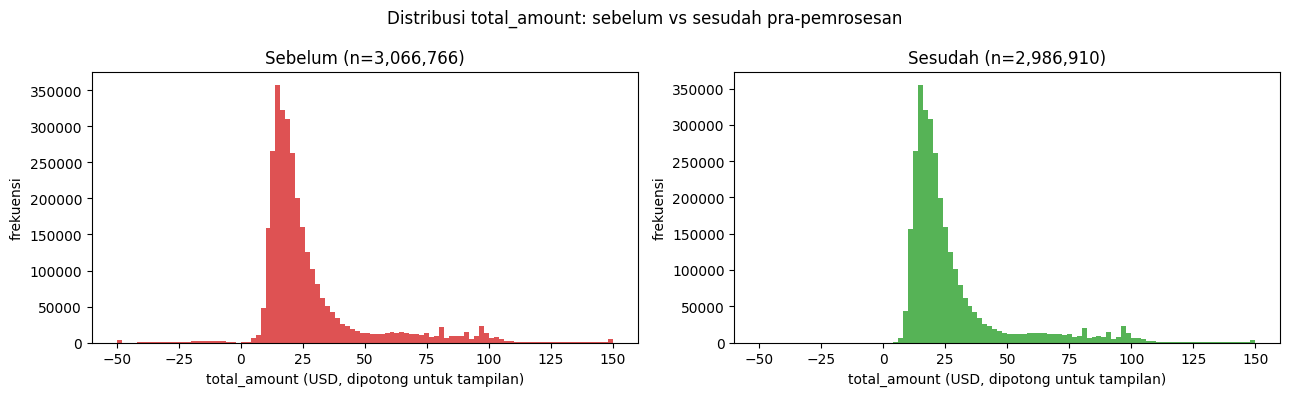

5

In [35]:
import matplotlib.pyplot as plt
mentah_total = pd.read_parquet(PATH_TRIP, columns=["total_amount"])["total_amount"]
RENTANG = (-50, 150)
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharex=True, sharey=False)
ax[0].hist(mentah_total.clip(*RENTANG), bins=100, range=RENTANG, color="tab:red", alpha=.8)
ax[0].set_title(f"Sebelum (n={len(mentah_total):,})")
ax[1].hist(bersih["total_amount"].clip(*RENTANG), bins=100, range=RENTANG, color="tab:green", alpha=.8)
ax[1].set_title(f"Sesudah (n={len(bersih):,})")
for a in ax:
    a.set_xlabel("total_amount (USD, dipotong untuk tampilan)")
    a.set_ylabel("frekuensi")
plt.suptitle("Distribusi total_amount: sebelum vs sesudah pra-pemrosesan")
plt.tight_layout()
plt.savefig(f"{DIR_SIMPAN}/hist_total_amount.png", dpi=150)
plt.show()
del mentah_total; gc.collect()

**Satu kalimat perubahan bentuk:** setelah pembersihan, nilai negatif/nol (refund, transaksi batal) di sisi kiri hilang dan ekor kanan yang ekstrem berkurang, tetapi distribusi tetap miring ke kanan karena tarif mahal (mis. bandara) sengaja dipertahankan dan hanya ditandai.

---
# P. Studi Kasus — Menyiapkan Data untuk Tim Penetapan Harga Dinamis
Dugaan tim *pricing*: **tarif per mil meningkat pada jam hujan di borough tertentu.**
Output yang diminta: tabel analitik (1 baris per borough per jam), `kamus_data.md`, jawaban dugaan dengan angka pembanding, ≥3 batasan, dan paragraf pembaruan otomatis bulanan.

**P-1. Tabel analitik** — median dipakai (bukan rerata) karena distribusi miring; kelompok < 30 perjalanan dibuang karena terlalu kecil untuk disimpulkan.

In [36]:
tabel_analitik = (bersih
    .assign(jam_mulai=bersih["tpep_pickup_datetime"].dt.floor("h"))
    .groupby(["borough_naik", "jam_mulai"], observed=True)
    .agg(jumlah_perjalanan=("total_amount", "size"),
         rata_tarif_per_mil=("tarif_per_mil", "median"),
         rata_kecepatan=("kecepatan_mph", "median"),
         suhu_c=("suhu_c", "first"), hujan=("hujan", "max"))
    .reset_index())
# Ambang minimum: kelompok yang terlalu kecil tidak bisa disimpulkan
tabel_analitik = tabel_analitik[tabel_analitik["jumlah_perjalanan"] >= 30]
print(tabel_analitik
      .groupby(["borough_naik", "hujan"], observed=True)["rata_tarif_per_mil"]
      .median().unstack())

hujan               0        1
borough_naik                  
Brooklyn       6.9430   7.6550
Manhattan     10.5270  11.4000
Queens         5.4530   5.6365
Unknown        8.7255   9.8860


**P-2. Jawaban dugaan** — perbandingan hujan vs tidak hujan per borough, lengkap dengan selisih dan jumlah jam-borough.

In [37]:
pivot = (tabel_analitik
         .groupby(["borough_naik", "hujan"], observed=True)["rata_tarif_per_mil"]
         .median().unstack())
pivot = pivot.rename(columns={0: "tidak_hujan", 1: "hujan"})
for kol in ("tidak_hujan", "hujan"):
    if kol not in pivot.columns:
        pivot[kol] = np.nan
pivot = pivot[["tidak_hujan", "hujan"]]
pivot["selisih"] = (pivot["hujan"] - pivot["tidak_hujan"]).round(3)
pivot["selisih_%"] = (100 * pivot["selisih"] / pivot["tidak_hujan"]).round(2)
n_jam = (tabel_analitik.groupby(["borough_naik", "hujan"], observed=True).size()
         .unstack().rename(columns={0: "jam_tdk_hujan", 1: "jam_hujan"}))
pivot = pivot.join(n_jam)
display(pivot)
naik = pivot.index[pivot["selisih"] > 0].tolist()
turun = pivot.index[pivot["selisih"] <= 0].tolist()
print("Borough dengan tarif/mil lebih tinggi saat hujan :", naik)
print("Borough tanpa kenaikan (sama/lebih rendah)        :", turun)

hujan,tidak_hujan,hujan,selisih,selisih_%,jam_tdk_hujan,jam_hujan
borough_naik,,,,,,
Brooklyn,6.9430,7.6550,0.712,10.25,125,17
Manhattan,10.5270,11.4000,0.873,8.29,637,107
Queens,5.4530,5.6365,0.183,3.36,583,96
Unknown,8.7255,9.8860,1.160,13.29,450,79


Borough dengan tarif/mil lebih tinggi saat hujan : ['Brooklyn', 'Manhattan', 'Queens', 'Unknown']
Borough tanpa kenaikan (sama/lebih rendah)        : []


In [38]:
# Simpan tabel analitik (Parquet) + kamus data studi kasus
tabel_analitik.to_parquet(f"{DIR_SIMPAN}/tabel_analitik.parquet", index=False)

KAMUS_ANALITIK = """## Bagian B - Tabel analitik (`tabel_analitik.parquet`)
Tingkat rincian: **satu baris per borough per jam**; kelompok dengan < 30 perjalanan dibuang.

| Kolom | Tipe | Satuan | Definisi / cara menghitung |
|---|---|---|---|
| borough_naik | string | - | Borough lokasi naik, dari join `PULocationID` ke `taxi_zone_lookup.csv` |
| jam_mulai | datetime | jam (waktu lokal NY) | `tpep_pickup_datetime` dibulatkan ke bawah per jam |
| jumlah_perjalanan | int | perjalanan | Jumlah baris bersih pada borough-jam tersebut |
| rata_tarif_per_mil | float | USD/mil | **Median** dari `total_amount / trip_distance` (median karena distribusi miring) |
| rata_kecepatan | float | mil/jam | **Median** dari `trip_distance / (durasi_menit / 60)` |
| suhu_c | float | derajat Celsius | Suhu 2 m per jam dari Open-Meteo (satu titik untuk seluruh kota) |
| hujan | int8 (0/1) | - | 1 bila curah hujan jam itu > 0,1 mm; agregasi `max` |
"""
with open(f"{DIR_SIMPAN}/kamus_data_studi_kasus.md", "w", encoding="utf-8") as f:
    f.write(KAMUS_ANALITIK)
print("tersimpan:", f"{DIR_SIMPAN}/tabel_analitik.parquet")

tersimpan: /content/drive/MyDrive/BigData/Praktikum3/tabel_analitik.parquet


**Jawaban dugaan.** Baca tabel `pivot`: kolom `selisih` dan `selisih_%` menunjukkan apakah tarif per mil median lebih tinggi pada jam hujan. Jika selisih positif di sebagian borough saja, dugaan **hanya didukung sebagian**; jika kecil atau tidak konsisten, dugaan **belum terbukti**. Sebutkan angka per borough dari output Anda.

**P-3. Batasan eksplisit (hasil tidak boleh dipercaya begitu saja bila):**
1. **Median, bukan rerata** — median tahan ekstrem tetapi tidak menunjukkan total pendapatan; kesimpulan hanya berlaku untuk perjalanan "tipikal".
2. **Cuaca satu titik untuk seluruh kota** — hujan di Manhattan belum tentu hujan di Queens/Staten Island, sehingga label `hujan` mengandung galat pengukuran.
3. **Korelasi bukan sebab-akibat** — hujan bisa bersamaan dengan jam sibuk, hari kerja, atau acara tertentu; tidak ada kontrol variabel perancu (jam, hari, jarak).
4. **Satu bulan data (Januari)** — jam hujan jumlahnya sedikit, kelompok kecil rentan noise; musim lain mungkin berbeda.
5. **`total_amount` memuat tip, pajak, dan biaya lain**, bukan hanya tarif argo, sehingga tarif/mil tidak murni harga dasar.

**P-4. Pembaruan otomatis bulanan.** Bungkus seluruh langkah menjadi pipeline terjadwal (mis. Cloud Scheduler/Airflow/cron) yang tiap awal bulan: (1) mengunduh file Parquet bulan baru dengan `unduh_aman` (cache + retry + penulisan atomik) dan memanggil API cuaca untuk rentang bulan itu; (2) menjalankan `pipeline()` yang tervalidasi dengan kontrak skema sehingga gagal keras bila skema berubah; (3) menulis hasil ke direktori berpartisi `bulan=YYYY-MM/` dengan mode *overwrite* per partisi agar idempoten (lihat `pipeline_inkremental` pada Latihan 6); (4) menghitung ulang tabel analitik dari lapisan terkurasi; dan (5) mencatat lineage (sumber, waktu ambil, jumlah baris, versi kode) serta laporan kualitas tiap bulan agar setiap angka dapat ditelusuri sampai sumbernya dan lonjakan kegagalan aturan memicu peringatan.

---
# Q. Latihan

### Latihan 1 (mudah) — Kecepatan unduhan MB/detik dan bukti cache

In [39]:
def unduh_aman_v2(url, tujuan, percobaan=3, jeda_awal=2):
    """Seperti unduh_aman, tetapi mencetak kecepatan unduhan (MB/detik)."""
    if os.path.exists(tujuan) and os.path.getsize(tujuan) > 0:
        print("cache ditemukan:", os.path.basename(tujuan), "-> tidak mengunduh (0 MB/detik)")
        return tujuan
    sementara = tujuan + ".part"
    for i in range(percobaan):
        try:
            t0 = time.perf_counter()
            with requests.get(url, stream=True, timeout=60) as r:
                r.raise_for_status()
                with open(sementara, "wb") as f:
                    shutil.copyfileobj(r.raw, f)
            detik = time.perf_counter() - t0
            ukuran = os.path.getsize(sementara)
            if ukuran == 0:
                raise IOError("berkas kosong")
            os.replace(sementara, tujuan)
            print(f"diunduh {ukuran/1024**2:.2f} MB dalam {detik:.2f} s "
                  f"-> {ukuran/1024**2/max(detik, 1e-9):.2f} MB/detik")
            return tujuan
        except Exception as e:
            jeda = jeda_awal * (2 ** i)
            print(f"percobaan {i+1} gagal ({e}); menunggu {jeda}s")
            time.sleep(jeda)
    raise RuntimeError(f"gagal mengunduh setelah {percobaan} percobaan: {url}")

PATH_L1 = os.path.join(DIR_MENTAH, "latihan1_trip.parquet")
if os.path.exists(PATH_L1):
    os.remove(PATH_L1)  # pastikan panggilan pertama benar-benar mengunduh
print("Panggilan 1:"); unduh_aman_v2(URL_TRIP, PATH_L1)
print("Panggilan 2:"); unduh_aman_v2(URL_TRIP, PATH_L1)
os.remove(PATH_L1)

Panggilan 1:
diunduh 45.46 MB dalam 0.53 s -> 86.34 MB/detik
Panggilan 2:
cache ditemukan: latihan1_trip.parquet -> tidak mengunduh (0 MB/detik)


**Interpretasi:** panggilan pertama mengunduh dan mencetak kecepatan; panggilan kedua mendeteksi file sudah ada sehingga memakai *cache* tanpa unduhan.

### Latihan 2 (mudah) — Dua aturan baru kualitas data
Aturan baru: **validitas** `tip_amount` antara 0 dan `total_amount`; **konsistensi** dua kolom: `total_amount >= fare_amount + tip_amount`.

In [40]:
aturan_baru = {
    "validitas: tip_amount 0 s.d. total_amount": (trip["tip_amount"] >= 0) & (trip["tip_amount"] <= trip["total_amount"]),
    "konsistensi: total >= fare + tip": trip["total_amount"] >= (trip["fare_amount"] + trip["tip_amount"]),
}
laporan_baru = pd.DataFrame([
    {"aturan": nama, "lulus": int(mask.sum()), "gagal": int((~mask).sum()),
     "persen_gagal": round(100 * (~mask).mean(), 3)}
    for nama, mask in aturan_baru.items()
])
laporan_baru

,aturan,lulus,gagal,persen_gagal
0,validitas: tip_amount 0 s.d. total_amount,3041558,25207,0.822
1,konsistensi: total >= fare + tip,3041605,25160,0.820


**Interpretasi:** persentase gagal pada tabel menunjukkan seberapa sering tip negatif/melebihi total, atau total lebih kecil dari tarif+tip (biasanya refund atau data tidak konsisten).

### Latihan 3 (sedang) — Join lokasi tujuan dan 10 pasangan borough asal–tujuan tersibuk

In [41]:
zona_tujuan = zona[["LocationID", "Borough"]].rename(columns={"Borough": "borough_turun"})
print("kunci zona unik?", zona_tujuan["LocationID"].is_unique)
n0 = len(bersih)
bersih_do = (bersih[["PULocationID", "DOLocationID", "borough_naik"]]
             .merge(zona_tujuan, left_on="DOLocationID", right_on="LocationID",
                    how="left", validate="many_to_one")
             .drop(columns="LocationID"))
print(f"baris {n0:,} -> {len(bersih_do):,} (harus sama)")
pasangan = (bersih_do.groupby(["borough_naik", "borough_turun"]).size()
            .sort_values(ascending=False).head(10).rename("jumlah_perjalanan"))
pasangan

kunci zona unik? True
baris 2,986,910 -> 2,986,910 (harus sama)


borough_naik  borough_turun
Manhattan     Manhattan        2491566
Queens        Manhattan         155261
Manhattan     Queens             82354
              Brooklyn           62986
Queens        Queens             59146
              Brooklyn           42187
Unknown       Manhattan          18432
              Unknown            13562
Manhattan     Bronx               8865
Brooklyn      Brooklyn            7910
Name: jumlah_perjalanan, dtype: int64

**Interpretasi:** pasangan teratas hampir pasti perjalanan di dalam borough yang sama (mis. Manhattan→Manhattan), diikuti arus dari/ke Queens (bandara).

### Latihan 4 (sedang) — MinMaxScaler vs StandardScaler

In [42]:
from sklearn.preprocessing import MinMaxScaler
mm = MinMaxScaler().fit(latih[FITUR_NUM])  # fit hanya di data latih
latih_mm = mm.transform(latih[FITUR_NUM])
uji_mm = mm.transform(uji[FITUR_NUM])
rentang = pd.DataFrame({
    "std_scaler_min": latih_num.min(axis=0), "std_scaler_max": latih_num.max(axis=0),
    "minmax_min_latih": latih_mm.min(axis=0), "minmax_max_latih": latih_mm.max(axis=0),
    "minmax_min_uji": uji_mm.min(axis=0), "minmax_max_uji": uji_mm.max(axis=0),
}, index=FITUR_NUM).round(3)
rentang

,std_scaler_min,std_scaler_max,minmax_min_latih,minmax_max_latih,minmax_min_uji,minmax_max_uji
trip_distance_capped,-0.794,4.247,0.0,1.0,0.0,1.00
durasi_menit,-1.226,13.925,0.0,1.0,0.0,0.91
suhu_c,-2.288,3.347,0.0,1.0,0.0,1.00


**Interpretasi:** `StandardScaler` menghasilkan mean 0 & std 1 (rentang tidak terbatas), `MinMaxScaler` memaksa data latih ke [0, 1] (data uji bisa keluar dari [0,1] bila ada nilai di luar rentang latih). **Penting** untuk algoritma berbasis jarak/gradien (k-NN, SVM, K-Means, regresi dengan regularisasi, jaringan saraf); **tidak penting** untuk model berbasis pohon (Decision Tree, Random Forest, Gradient Boosting) karena hanya bergantung pada urutan nilai.

### Latihan 5 (sedang) — Membuktikan `validate="many_to_one"`

In [43]:
from pandas.errors import MergeError
zona_rusak = pd.concat([zona, zona.iloc[[0]]], ignore_index=True)  # satu baris digandakan (salinan)
print("kunci unik di zona_rusak?", zona_rusak["LocationID"].is_unique)
uji_df = trip[["PULocationID"]].head(1000)
try:
    uji_df.merge(zona_rusak[["LocationID", "Borough"]], left_on="PULocationID",
                 right_on="LocationID", how="left", validate="many_to_one")
    print("TIDAK ada error (tidak diharapkan)")
except MergeError as e:
    print("MergeError muncul seperti diharapkan:\n ", e)
# Tabel asli tidak berubah (kita bekerja pada salinan)
print("zona asli:", len(zona), "baris | kunci unik?", zona["LocationID"].is_unique)
# Tanpa validate, baris diam-diam menggandakan:
tanpa_validate = uji_df.merge(zona_rusak[["LocationID", "Borough"]], left_on="PULocationID",
                              right_on="LocationID", how="left")
print(f"tanpa validate: {len(uji_df)} -> {len(tanpa_validate)} baris (ledakan baris diam-diam)")

kunci unik di zona_rusak? False
MergeError muncul seperti diharapkan:
  Merge keys are not unique in right dataset; not a many-to-one merge
zona asli: 265 baris | kunci unik? True
tanpa validate: 1000 -> 1000 baris (ledakan baris diam-diam)


**Interpretasi:** dengan `validate="many_to_one"` kunci ganda di tabel kanan menghentikan proses lewat `MergeError`. Tanpa parameter itu, baris transaksi tergandakan tanpa peringatan.

### Latihan 6 (menantang) — `pipeline_inkremental(bulan)` idempoten
Hanya memproses bulan yang belum ada di direktori keluaran. Keluaran dipartisi `bulan=YYYY-MM/borough_naik=.../`.

In [44]:
DIR_INK = os.path.join(DIR_KURASI, "trips_bersih_bulanan")
URL_BASE = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_{bulan}.parquet"

def muat_cuaca(mulai, selesai):
    """Ambil cuaca dari API; bila gagal, pakai data sintetis (dicatat di lineage)."""
    try:
        df = ambil_cuaca(mulai, selesai)
        df["time"] = pd.to_datetime(df["time"])
        df = df.rename(columns={"time": "jam_mulai", "temperature_2m": "suhu_c",
                                "precipitation": "hujan_mm"})
        catat_sumber(f"cuaca {mulai[:7]}", API_CUACA, len(df), "Open-Meteo hourly archive")
    except Exception as e:
        print("API cuaca gagal, memakai sintetis:", e)
        df = cuaca_sintetis(mulai, selesai)
        catat_sumber(f"cuaca {mulai[:7]}", "sintetis", len(df), "PENGGANTI - bukan data nyata")
    return df

def hitung_berkas(d):
    return sum(len(f) for _, _, f in os.walk(d)) if os.path.isdir(d) else 0

def pipeline_inkremental(bulan, paksa=False):
    """bulan: 'YYYY-MM'. Memproses hanya bila partisi bulan itu belum ada."""
    tujuan = os.path.join(DIR_INK, f"bulan={bulan}")
    if os.path.isdir(tujuan) and hitung_berkas(tujuan) > 0 and not paksa:
        print(f"[{bulan}] sudah ada di keluaran -> dilewati")
        return None
    path = unduh_aman(URL_BASE.format(bulan=bulan),
                      os.path.join(DIR_MENTAH, f"yellow_tripdata_{bulan}.parquet"))
    mulai = pd.Timestamp(bulan + "-01")
    selesai = mulai + pd.offsets.MonthEnd(0)
    cu = muat_cuaca(mulai.strftime("%Y-%m-%d"), selesai.strftime("%Y-%m-%d"))
    df = pipeline(path, PATH_ZONA, cu, tarif_referensi)
    df["bulan"] = bulan
    if os.path.isdir(tujuan):
        shutil.rmtree(tujuan)  # overwrite partisi bulan ini saja
    df.to_parquet(DIR_INK, partition_cols=["bulan", "borough_naik"], index=False)
    catat_sumber(f"trip {bulan} (bersih)", URL_BASE.format(bulan=bulan), len(df), "hasil pipeline_inkremental")
    return len(df)

In [45]:
# Bukti idempotensi pada bulan 2023-01
if os.path.isdir(DIR_INK):
    shutil.rmtree(DIR_INK)  # mulai bersih agar demonstrasi jelas
r1 = pipeline_inkremental("2023-01")
berkas_1 = hitung_berkas(DIR_INK)
r2 = pipeline_inkremental("2023-01")  # harus dilewati
berkas_2 = hitung_berkas(DIR_INK)
print(f"panggilan 1: {r1:,} baris, berkas = {berkas_1}")
print(f"panggilan 2: {r2}, berkas = {berkas_2}")
print("idempoten (tidak ada berkas baru)?", berkas_1 == berkas_2)

cache ditemukan: yellow_tripdata_2023-01.parquet
[lineage] cuaca 2023-01: 744 baris
Validasi lulus: 2,986,910 baris x 17 kolom
[lineage] trip 2023-01 (bersih): 2,986,910 baris
[2023-01] sudah ada di keluaran -> dilewati
panggilan 1: 2,986,910 baris, berkas = 8
panggilan 2: None, berkas = 8
idempoten (tidak ada berkas baru)? True


**Interpretasi:** panggilan kedua mengembalikan `None` dan jumlah berkas tidak bertambah, bukti pipeline idempoten.

---
# R. Tugas Praktikum

### R-1. Pipeline dua bulan (Januari & Juli 2023) ke direktori berpartisi yang sama
Januari sudah dikerjakan di Latihan 6; sekarang Juli ditambahkan ke `DIR_INK` yang sama lalu diperiksa tidak ada duplikasi antar-bulan.

In [46]:
for b in ["2023-01", "2023-07"]:
    pipeline_inkremental(b)
print("\nberkas total:", hitung_berkas(DIR_INK))
print("partisi bulan:", sorted(d for d in os.listdir(DIR_INK) if d.startswith("bulan=")))

[2023-01] sudah ada di keluaran -> dilewati
cache ditemukan: yellow_tripdata_2023-07.parquet
[lineage] cuaca 2023-07: 744 baris
Validasi lulus: 2,817,657 baris x 17 kolom
[lineage] trip 2023-07 (bersih): 2,817,657 baris

berkas total: 16
partisi bulan: ['bulan=2023-01', 'bulan=2023-07']


In [47]:
# Bukti tidak ada duplikasi (dalam bulan maupun antar-bulan)
ds = pd.read_parquet(DIR_INK, columns=KUNCI + ["bulan"])
ds["bulan"] = ds["bulan"].astype(str)
print(ds.groupby("bulan").size().rename("baris").to_frame())
dup_dalam = ds.duplicated(subset=KUNCI + ["bulan"]).sum()
dup_antar = ds.duplicated(subset=KUNCI).sum()
print(f"duplikat dalam bulan : {dup_dalam:,}")
print(f"duplikat antar bulan : {dup_antar:,}")
print("Tanpa duplikasi?", dup_dalam == 0 and dup_antar == 0)
# Menjalankan ulang tidak menambah berkas
b0 = hitung_berkas(DIR_INK)
for b in ["2023-01", "2023-07"]:
    pipeline_inkremental(b)
print("jalankan ulang -> berkas tetap?", hitung_berkas(DIR_INK) == b0)
del ds; gc.collect()

           baris
bulan           
2023-01  2986910
2023-07  2817657
duplikat dalam bulan : 0
duplikat antar bulan : 0
Tanpa duplikasi? True
[2023-01] sudah ada di keluaran -> dilewati
[2023-07] sudah ada di keluaran -> dilewati
jalankan ulang -> berkas tetap? True


147

### R-2. Laporan kualitas komparatif (Januari vs Juli 2023)
Aturan K-6 dijalankan pada data mentah tiap bulan; kolom perubahan menyoroti aturan yang berubah signifikan (> 1 poin persentase).

In [48]:
def laporan_bulan(bulan):
    path = os.path.join(DIR_MENTAH, f"yellow_tripdata_{bulan}.parquet")
    df = pd.read_parquet(path, columns=KOLOM)
    df["durasi_menit"] = ((df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"])
                          .dt.total_seconds() / 60)
    awal = pd.Timestamp(bulan + "-01"); akhir = awal + pd.offsets.MonthBegin(1)
    ar = {
        "kelengkapan: passenger_count ada": df["passenger_count"].notna(),
        "keunikan: baris tidak duplikat": ~df.duplicated(),
        "validitas: jarak 0-100 mil": df["trip_distance"].between(0.01, 100),
        "validitas: total_amount > 0": df["total_amount"] > 0,
        "validitas: PULocationID dikenal": df["PULocationID"].isin(zona_sah),
        "konsistensi: durasi 1-180 menit": df["durasi_menit"].between(1, 180),
        "konsistensi: total >= fare": df["total_amount"] >= df["fare_amount"],
        "ketepatan waktu: dalam bulan file": df["tpep_pickup_datetime"].between(awal, akhir),
    }
    out = pd.DataFrame([{"aturan": n, f"gagal_%_{bulan}": round(100 * (~m).mean(), 3)}
                        for n, m in ar.items()])
    del df; gc.collect()
    return out

lap_jan = laporan_bulan("2023-01")
lap_jul = laporan_bulan("2023-07")
komparatif = lap_jan.merge(lap_jul, on="aturan", validate="one_to_one")
komparatif["perubahan_poin"] = (komparatif["gagal_%_2023-07"] - komparatif["gagal_%_2023-01"]).round(3)
komparatif["berubah_signifikan"] = komparatif["perubahan_poin"].abs() > 1
komparatif = komparatif.sort_values("perubahan_poin", key=lambda s: s.abs(), ascending=False)
komparatif.to_csv(f"{DIR_SIMPAN}/laporan_kualitas_komparatif.csv", index=False)
komparatif

,aturan,gagal_%_2023-01,gagal_%_2023-07,perubahan_poin,berubah_signifikan
0,kelengkapan: passenger_count ada,2.339,2.927,0.588,False
6,konsistensi: total >= fare,0.816,1.053,0.237,False
3,validitas: total_amount > 0,0.840,1.075,0.235,False
2,validitas: jarak 0-100 mil,1.498,1.717,0.219,False
5,konsistensi: durasi 1-180 menit,1.186,1.311,0.125,False
1,keunikan: baris tidak duplikat,0.000,0.000,0.000,False
4,validitas: PULocationID dikenal,0.000,0.000,0.000,False
7,ketepatan waktu: dalam bulan file,0.002,0.002,0.000,False


**Interpretasi:** aturan dengan `berubah_signifikan = True` adalah yang tingkat kegagalannya bergeser > 1 poin persentase antarbulan. Dugaan penyebab yang lazim: perubahan pada sistem pelaporan vendor/perangkat argo (kelengkapan `passenger_count`), perubahan kebijakan tarif atau biaya, dan volume refund musiman. Tulis dugaan Anda untuk tiap aturan yang berubah, berdasarkan tabel ini.

### R-3. Sumber keempat — Hari libur nasional AS (API publik Nager.Date)
**Akuisisi:** `GET https://date.nager.at/api/v3/PublicHolidays/{tahun}/US` — API publik gratis, tanpa kunci, data hari libur (informasi publik, legal dipakai). Respons divalidasi, dicoba ulang untuk 429/5xx, dan ada cadangan statis bila internet diblokir.
**Integrasi:** granularitas respons = per tanggal; dibuat unik per tanggal lalu di-*join* `many_to_one` ke data trip lewat tanggal naik, sehingga baris tidak berubah.

In [49]:
URL_LIBUR = "https://date.nager.at/api/v3/PublicHolidays/{tahun}/US"

def ambil_libur(tahun, percobaan=3):
    for i in range(percobaan):
        r = requests.get(URL_LIBUR.format(tahun=tahun), timeout=60)
        if r.status_code == 200:
            data = r.json()
            if not isinstance(data, list) or not data or "date" not in data[0]:
                raise ValueError("struktur respons hari libur tidak sesuai")
            df = pd.DataFrame(data)[["date", "name"]]
            df["tanggal"] = pd.to_datetime(df["date"])
            return df.groupby("tanggal", as_index=False).agg(nama_libur=("name", " / ".join))
        if r.status_code in (429, 500, 502, 503):
            time.sleep(2 ** i); continue
        r.raise_for_status()
    raise RuntimeError("API hari libur tidak merespons dengan benar")

try:
    libur = ambil_libur(2023)
    catat_sumber("libur_as_2023", URL_LIBUR.format(tahun=2023), len(libur), "Nager.Date PublicHolidays US")
except Exception as e:
    print("API hari libur gagal, memakai cadangan statis:", e)
    libur = pd.DataFrame({
        "tanggal": pd.to_datetime(["2023-01-01", "2023-01-02", "2023-01-16", "2023-07-04"]),
        "nama_libur": ["New Year's Day", "New Year's Day (observed)", "Martin Luther King, Jr. Day", "Independence Day"],
    })
    catat_sumber("libur_as_2023", "cadangan statis", len(libur), "PENGGANTI - bukan data API")

print("kunci tanggal unik?", libur["tanggal"].is_unique)
hasil_v2 = hasil.copy()
hasil_v2["tanggal_dt"] = hasil_v2["tpep_pickup_datetime"].dt.normalize()
n0 = len(hasil_v2)
hasil_v2 = (hasil_v2.merge(libur, left_on="tanggal_dt", right_on="tanggal",
                           how="left", validate="many_to_one", suffixes=("", "_libur"))
            .drop(columns=["tanggal_dt", "tanggal_libur"]))
hasil_v2["hari_libur"] = hasil_v2["nama_libur"].notna().astype("int8")
print(f"baris {n0:,} -> {len(hasil_v2):,} (harus sama)")
print(hasil_v2.groupby("hari_libur")["total_amount"].agg(["size", "median"]))

[lineage] libur_as_2023: 14 baris
kunci tanggal unik? True
baris 2,986,910 -> 2,986,910 (harus sama)
               size  median
hari_libur                 
0           2845518   20.16
1            141392   19.60


**Interpretasi:** kolom `hari_libur` (0/1) dan `nama_libur` kini tersedia sebagai fitur tambahan. Median `total_amount` pada hari libur vs hari biasa dapat dibandingkan sebagai langkah awal analisis lanjutan. Sumber baru dicatat di lineage.

### R-4. Kamus data (`kamus_data.md`) untuk seluruh kolom dataset akhir

In [50]:
KAMUS = {
 "tpep_pickup_datetime": ("TLC Yellow Taxi (Parquet)", "datetime", "waktu lokal NY", "Harus dalam bulan file; di luar bulan = ditandai di laporan kualitas", "Tidak ada yang hilang pada kolom ini"),
 "tpep_dropoff_datetime": ("TLC Yellow Taxi (Parquet)", "datetime", "waktu lokal NY", "Harus > waktu naik (durasi 1-180 menit)", "Tidak diisi; baris tidak lolos filter durasi dibuang"),
 "passenger_count": ("TLC Yellow Taxi (Parquet)", "float", "orang", "Bilangan bulat >= 0", "Diisi median per jam naik, lalu median global"),
 "trip_distance": ("TLC Yellow Taxi (Parquet)", "float", "mil", "0,01 - 100 mil", "Tidak ada hilang; di luar rentang dibuang"),
 "PULocationID": ("TLC Yellow Taxi (Parquet)", "int", "ID zona", "Harus ada di taxi_zone_lookup", "Zona tak dikenal -> borough NaN/Unknown"),
 "DOLocationID": ("TLC Yellow Taxi (Parquet)", "int", "ID zona", "Harus ada di taxi_zone_lookup", "Tidak diisi"),
 "payment_type": ("TLC Yellow Taxi (Parquet)", "int", "kode 1-6", "Harus ada di tabel tarif_referensi", "Tidak diisi"),
 "fare_amount": ("TLC Yellow Taxi (Parquet)", "float", "USD", "Total >= fare pada kondisi normal", "Tidak diisi"),
 "tip_amount": ("TLC Yellow Taxi (Parquet)", "float", "USD", ">= 0 dan <= total_amount", "Tidak diisi (tip tunai tidak tercatat)"),
 "total_amount": ("TLC Yellow Taxi (Parquet)", "float", "USD", "> 0", "Tidak diisi; baris <= 0 dibuang"),
 "durasi_menit": ("Turunan: dropoff - pickup", "float", "menit", "1 - 180 menit", "Tidak ada hilang"),
 "jam": ("Turunan: jam dari pickup", "int", "jam (0-23)", "0 - 23", "Tidak ada hilang"),
 "borough_naik": ("Join taxi_zone_lookup.csv", "string", "-", "Salah satu borough resmi atau Unknown", "Left join; tak cocok -> NaN"),
 "nama_pembayaran": ("Join tabel tarif_referensi (SQLite)", "string", "-", "Salah satu dari 6 nama pembayaran", "Left join; tak cocok -> NaN"),
 "jam_mulai": ("Turunan: pickup dibulatkan ke jam", "datetime", "jam", "Kunci join cuaca", "Tidak ada hilang"),
 "suhu_c": ("Open-Meteo Archive API", "float", "derajat Celsius", "Rentang wajar suhu NY", "NaN bila jam tidak ada di API (tidak diisi)"),
 "hujan_mm": ("Open-Meteo Archive API", "float", "mm per jam", ">= 0", "NaN bila jam tidak ada; diperlakukan 0 saat membuat fitur hujan"),
 "tanggal": ("Turunan: tanggal pickup (teks)", "string", "YYYY-MM-DD", "Dalam periode file", "Tidak ada hilang"),
 "nama_libur": ("Nager.Date API (sumber ke-4)", "string", "-", "Nama hari libur AS", "NaN = bukan hari libur"),
 "hari_libur": ("Turunan: nama_libur tidak kosong", "int8 (0/1)", "-", "0 atau 1", "Tidak ada hilang"),
}
kolom_akhir = list(hasil_v2.columns)
kurang = [k for k in kolom_akhir if k not in KAMUS]
print("kolom tanpa definisi di kamus:", kurang)
baris_md = ["# Kamus Data - Praktikum 3 Big Data", "",
            "## Bagian A - Dataset akhir (`trips_bersih/`)", "",
            "| Kolom | Tipe (aktual) | Satuan | Sumber | Aturan validitas | Penanganan nilai hilang |",
            "|---|---|---|---|---|---|"]
for k in kolom_akhir:
    sumber, tipe, satuan, validitas, hilang = KAMUS.get(k, ("-", "-", "-", "-", "-"))
    baris_md.append(f"| {k} | {hasil_v2[k].dtype} | {satuan} | {sumber} | {validitas} | {hilang} |")
isi_kamus = "\n".join(baris_md) + "\n\n" + KAMUS_ANALITIK
with open(f"{DIR_SIMPAN}/kamus_data.md", "w", encoding="utf-8") as f:
    f.write(isi_kamus)
print(f"kamus_data.md tersimpan ({len(kolom_akhir)} kolom dataset akhir + tabel analitik)")

kolom tanpa definisi di kamus: []
kamus_data.md tersimpan (20 kolom dataset akhir + tabel analitik)


### R-5. Dokumen lineage — diagram alur sumber → dataset akhir
Diagram satu halaman menandai setiap titik transformasi dan pembuangan baris (angka dari eksekusi Anda).

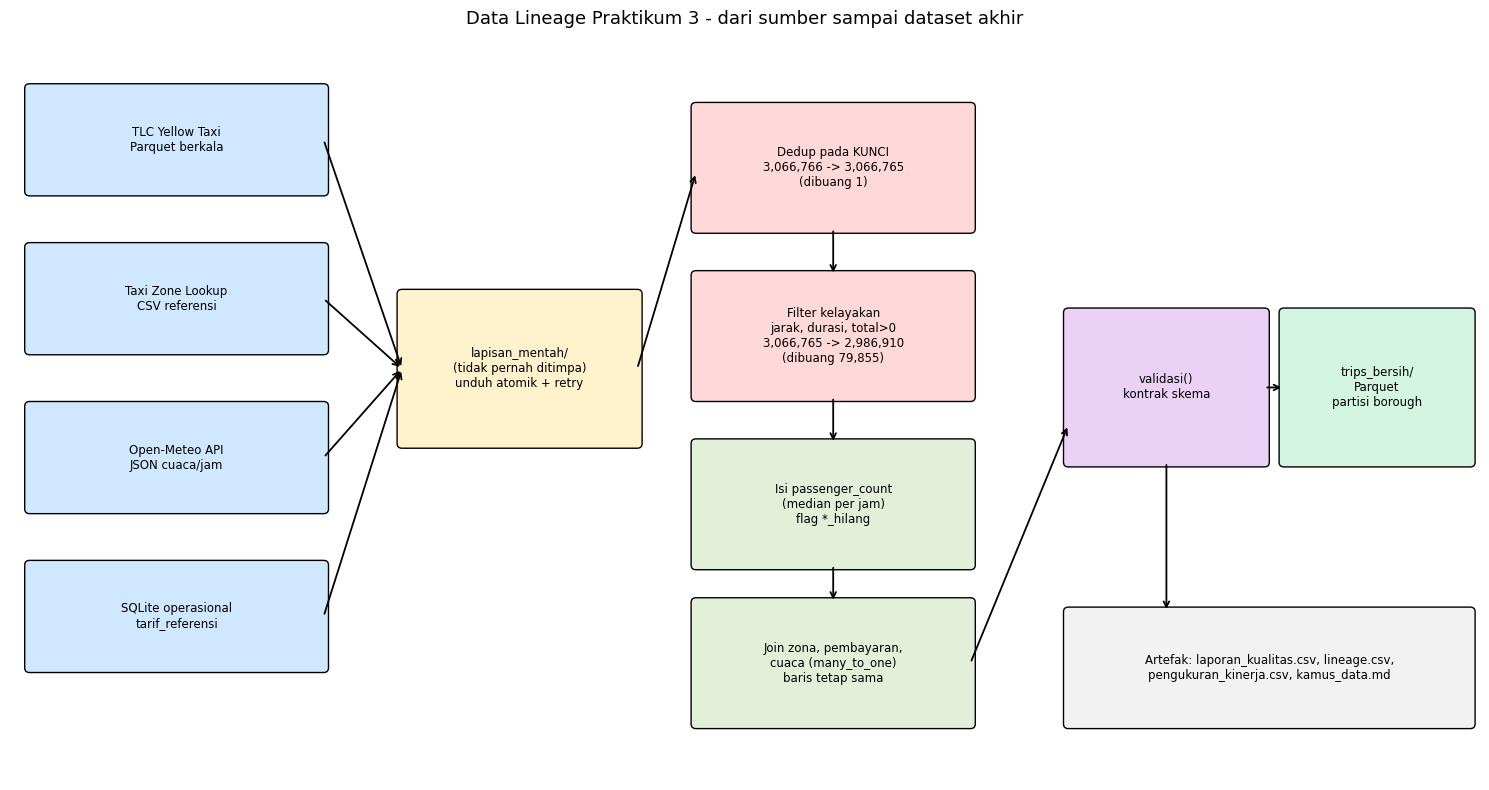

In [51]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15, 8))
ax.set_xlim(0, 15); ax.set_ylim(0, 8); ax.axis("off")

def kotak(x, y, w, h, teks, warna):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=warna, ec="black"))
    ax.text(x + w/2, y + h/2, teks, ha="center", va="center", fontsize=8.5)

def panah(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.3))

# Sumber
kotak(0.2, 6.3, 3.0, 1.1, "TLC Yellow Taxi\nParquet berkala", "#cfe8ff")
kotak(0.2, 4.6, 3.0, 1.1, "Taxi Zone Lookup\nCSV referensi", "#cfe8ff")
kotak(0.2, 2.9, 3.0, 1.1, "Open-Meteo API\nJSON cuaca/jam", "#cfe8ff")
kotak(0.2, 1.2, 3.0, 1.1, "SQLite operasional\ntarif_referensi", "#cfe8ff")
# Lapisan mentah
kotak(4.0, 3.6, 2.4, 1.6, "lapisan_mentah/\n(tidak pernah ditimpa)\nunduh atomik + retry", "#fff2cc")
for y in (6.85, 5.15, 3.45, 1.75):
    panah(3.2, y, 4.0, 4.4)
# Transformasi
kotak(7.0, 5.9, 2.8, 1.3, f"Dedup pada KUNCI\n{n_mentah:,} -> {n_setelah_dup:,}\n(dibuang {n_mentah-n_setelah_dup:,})", "#ffd9d9")
kotak(7.0, 4.1, 2.8, 1.3, f"Filter kelayakan\njarak, durasi, total>0\n{n_setelah_dup:,} -> {len(bersih):,}\n(dibuang {n_setelah_dup-len(bersih):,})", "#ffd9d9")
kotak(7.0, 2.3, 2.8, 1.3, "Isi passenger_count\n(median per jam)\nflag *_hilang", "#e2f0d9")
kotak(7.0, 0.6, 2.8, 1.3, "Join zona, pembayaran,\ncuaca (many_to_one)\nbaris tetap sama", "#e2f0d9")
panah(6.4, 4.4, 7.0, 6.5); panah(8.4, 5.9, 8.4, 5.4); panah(8.4, 4.1, 8.4, 3.6); panah(8.4, 2.3, 8.4, 1.9)
# Keluaran
kotak(10.8, 3.4, 2.0, 1.6, "validasi()\nkontrak skema", "#ead1f5")
panah(9.8, 1.25, 10.8, 3.8)
kotak(13.0, 3.4, 1.9, 1.6, "trips_bersih/\nParquet\npartisi borough", "#d5f5e3")
panah(12.8, 4.2, 13.0, 4.2)
kotak(10.8, 0.6, 4.1, 1.2, "Artefak: laporan_kualitas.csv, lineage.csv,\npengukuran_kinerja.csv, kamus_data.md", "#f2f2f2")
panah(11.8, 3.4, 11.8, 1.8)
ax.set_title("Data Lineage Praktikum 3 - dari sumber sampai dataset akhir", fontsize=13)
plt.tight_layout()
plt.savefig(f"{DIR_SIMPAN}/lineage_diagram.png", dpi=150)
plt.show()

### R-6. Reproducibility
- Seluruh notebook harus lulus **Runtime → Restart and run all** pada runtime bersih.
- Pipeline memakai *cache* unduhan, penulisan atomik, `rmtree`/`overwrite` sebelum menulis Parquet, dan `validate=` pada setiap join — sehingga aman dijalankan ulang.
- Sel di bawah menyimpan ulang semua artefak final ke Drive (termasuk lineage terbaru yang sudah memuat sumber keempat) dan memeriksa kelengkapan berkas yang dikumpulkan.

In [52]:
# Simpan ulang artefak final (lineage & kinerja sudah diperbarui)
laporan.to_csv(f"{DIR_SIMPAN}/laporan_kualitas.csv", index=False)
pd.DataFrame(lineage).to_csv(f"{DIR_SIMPAN}/lineage.csv", index=False)
pd.DataFrame(catatan).to_csv(f"{DIR_SIMPAN}/pengukuran_kinerja.csv", index=False)
shutil.make_archive(f"{DIR_SIMPAN}/trips_bersih", "zip", OUT)

wajib = ["laporan_kualitas.csv", "lineage.csv", "kamus_data.md", "trips_bersih.zip"]
ada = set(os.listdir(DIR_SIMPAN))
for w in wajib:
    print(("OK      " if w in ada else "KURANG  "), w)
print("\nIsi folder Drive:")
for f in sorted(ada):
    p = os.path.join(DIR_SIMPAN, f)
    print(f"  {f:40s} {os.path.getsize(p)/1024:12.1f} KB")
print("\nCatatan: simpan notebook (.ipynb) dengan output, dan susun laporan PDF dari hasil di atas.")

OK       laporan_kualitas.csv
OK       lineage.csv
OK       kamus_data.md
OK       trips_bersih.zip

Isi folder Drive:
  hist_total_amount.png                            62.0 KB
  kamus_data.md                                     3.5 KB
  kamus_data_studi_kasus.md                         0.9 KB
  laporan_kualitas.csv                              0.4 KB
  laporan_kualitas_komparatif.csv                   0.5 KB
  lineage.csv                                       1.3 KB
  lineage_diagram.png                             162.5 KB
  pengukuran_kinerja.csv                            0.2 KB
  tabel_analitik.parquet                           43.2 KB
  trips_bersih                                      4.0 KB
  trips_bersih.zip                              57127.9 KB

Catatan: simpan notebook (.ipynb) dengan output, dan susun laporan PDF dari hasil di atas.


---
# S. Pertanyaan Evaluasi

**1. Perbedaan ETL dan ELT; mengapa ELT lebih lazim.**
ETL (*Extract-Transform-Load*) mentransformasi data **sebelum** disimpan ke tujuan, sehingga hanya data terolah yang tersimpan. ELT (*Extract-Load-Transform*) menyimpan data **mentah dulu**, transformasi dilakukan belakangan di dalam sistem penyimpanan. ELT lebih lazim pada Big Data karena penyimpanan murah dan terdistribusi, skema/definisi bisnis sering berubah (data mentah bisa diproses ulang), dan mesin penyimpanan modern (data lake/warehouse, Spark) mampu mengolah data besar secara paralel.

**2. Tiga risiko akuisisi lewat API dan penanganannya.**
(a) *Batas laju* (HTTP 429) → jeda antar permintaan dan *exponential backoff*. (b) *Gangguan sementara server* (5xx) → *retry* berjeda dengan batas percobaan. (c) *Skema respons berubah / data tidak lengkap / paginasi* → validasi struktur JSON (cek kunci wajib) dan tangani halaman demi halaman. **Layak dicoba ulang:** 429, 500, 502, 503 (umumnya 5xx). **Tidak layak:** galat 4xx lain seperti 400, 401, 403, 404 karena tidak membaik dengan pengulangan.

**3. MCAR, MAR, MNAR.**
MCAR: hilang sepenuhnya acak, tak bergantung variabel apa pun. MAR: hilang bergantung pada variabel lain yang teramati (mis. kolom kosong lebih sering pada jam tertentu). MNAR: hilang bergantung pada **nilainya sendiri**. Contoh MNAR pada data transaksi: `tip_amount` tunai tidak dicatat justru ketika tip-nya besar/bernilai tertentu, atau tarif besar sengaja tidak dicatat. Pengisian nilai berbahaya karena nilai pengganti (median/rerata) menutupi pola penyebab hilangnya data dan menimbulkan bias; lebih baik nilai hilang ditandai (`_hilang`) sebagai informasi.

**4. Mengapa Z-score kurang sesuai untuk data miring ke kanan; metode yang lebih baik.**
Z-score memakai rerata dan simpangan baku, yang sendiri ditarik oleh ekor panjang; akibatnya simpangan baku membesar, ambang 3σ menjadi terlalu jauh, dan banyak outlier tidak terdeteksi (*masking*). Selain itu ia mengandaikan distribusi mendekati normal. **IQR** lebih baik karena berbasis kuartil yang kokoh terhadap nilai ekstrem dan skewness; alternatif lain: transformasi log sebelum Z-score, winsorizing, atau menandai baris.

**5. Kunci ganda pada tabel referensi di join many-to-one.**
Satu baris transaksi berpasangan dengan beberapa baris referensi sehingga jumlah baris **bertambah** (ledakan baris) dan agregasi seperti jumlah/rerata menjadi salah. Dua cara mencegah: (1) periksa keunikan kunci sebelum join (`is_unique`/`drop_duplicates` pada tabel referensi) dan (2) gunakan `validate="many_to_one"` agar pandas melempar `MergeError`; juga bandingkan jumlah baris sebelum/sesudah join.

**6. Data leakage pada scaling; urutan langkah yang benar.**
Bila `fit` scaler dilakukan pada seluruh data, rerata dan simpangan baku ikut memuat informasi data uji sehingga evaluasi tampak lebih baik daripada kenyataan. Urutan benar: (1) pisahkan data latih dan uji (`train_test_split`) terlebih dulu; (2) `fit` scaler/encoder/pengisi nilai hilang **hanya** pada data latih; (3) `transform` data latih; (4) `transform` data uji dengan parameter yang sama (tanpa `fit` ulang). Praktik terbaik: bungkus dalam `Pipeline` scikit-learn.

**7. Pipeline idempoten dan dua tekniknya.**
Idempoten berarti menjalankan pipeline dua kali (atau lebih) menghasilkan keadaan akhir yang sama — tanpa duplikasi atau penumpukan. Teknik: (1) menulis keluaran dengan mode *overwrite* (hapus/timpa direktori keluaran atau partisi), (2) memakai kunci/penamaan yang deterministik dan cek *cache* (lewati bila hasil sudah ada); juga penulisan atomik (`.part` lalu `os.replace`) dan tidak melakukan *append* ke berkas yang sudah ada.

**8. Mengapa partisi kolom berkardinalitas tinggi merugikan; gejalanya.**
Setiap nilai unik menjadi satu direktori, sehingga terbentuk ribuan direktori/berkas kecil (*small files problem*). Gejala: penulisan dan pembacaan melambat, banyak waktu habis untuk *listing* metadata dan membuka berkas, overhead penjadwalan tugas Spark membengkak, kompresi dan *row group* tidak efisien, serta ukuran total meningkat. Pilih kolom partisi berkardinalitas rendah yang sering dipakai sebagai filter (mis. borough atau tanggal).

**9. Scraping ulasan e-commerce: empat hal yang diperiksa dan satu kondisi penolakan.**
Empat hal yang diperiksa dulu: (1) `robots.txt` situs; (2) syarat & ketentuan (ToS) tentang pengambilan data otomatis; (3) data pribadi pada ulasan (nama, foto, ID pengguna) dan kepatuhan pada hukum pelindungan data (mis. UU PDP, GDPR) serta etika penelitian/persetujuan etik; (4) ketersediaan API resmi/lisensi data dan batas laju/beban server (hak cipta atas ulasan). **Kondisi yang membuat harus menolak:** situs melarang eksplisit scraping (ToS/`robots.txt`) dan tidak ada izin tertulis, atau pengambilan mensyaratkan menembus login/proteksi teknis (CAPTCHA, pembatasan akses) maupun mengumpulkan data pribadi tanpa dasar hukum/persetujuan.